# 04. CNN (합성곱 신경망, Convolutional Neural Network)

## 🎯 이 노트북에서 배울 것
1. **합성곱(Convolution)**과 **풀링(Pooling)**이 이미지에서 무엇을 하는지 작은 예제로 눈으로 확인
2. PyTorch로 CNN을 만들고, **합성 이미지 데이터셋(원/사각형/삼각형)**을 분류하기
3. 각 층이 "왜" 필요한지 주석으로 이해하기

## 📖 핵심 개념
- **합성곱**: 작은 커널(필터)을 이미지 위에서 슬라이딩하며 가중합 → 엣지, 패턴 같은 **국소적 특징** 검출
- **가중치 공유**: 같은 커널을 이미지 전체에 재사용 → 파라미터 수 급감 + 위치 불변성
- **풀링(Max Pooling)**: 2×2 영역의 최댓값만 취함 → 크기를 줄이고, 약간의 위치 이동에 둔감해짐
- 전체 구조: `Conv → ReLU → Pool` 반복 (특징 추출) → `Flatten → FC` (분류)


In [1]:
import numpy as np
import matplotlib.pyplot as plt

import matplotlib.font_manager as fm
# 한글 라벨이 깨지지 않도록,환경에 설치된 한글/CJK 폰트를 자동으로 찾아 설정
# (Windows: Malgun Gothic, macOS: AppleGothic, 리눅스: Noto Sans CJK KR 등)
_cjk_fonts = ["Malgun Gothic", "AppleGothic", "Noto Sans CJK KR", "Noto Sans KR",
              "NanumGothic", "WenQuanYi Zen Hei", "DejaVu Sans"]
_installed = {f.name for f in fm.fontManager.ttflist}
for _name in _cjk_fonts:
    if _name in _installed:
        plt.rcParams["font.family"] = _name
        break

rng = np.random.default_rng(0)


## 1) 미니 예제: 5×5 이미지에 3×3 커널을 "수작업"으로 합성곱

아래에서 커널이 이미지 위를 한 칸씩 움직이며(슬라이딩 윈도우) 가중합을 계산하는 과정을 눈으로 확인하세요.
사용하는 커널은 **세로 엣지 검출** 커널입니다.


In [2]:
image = np.array([
    [1, 1, 0, 0, 1],
    [1, 2, 1, 0, 1],
    [0, 1, 2, 1, 0],
    [0, 0, 1, 2, 1],
    [1, 0, 0, 1, 2],
], dtype=float)

# 세로 엣지 검출 커널: 왼쪽은 +, 오른쪽은 − → 세로 경계에서 큰 값 출력
kernel = np.array([[1, 0, -1],
                   [1, 0, -1],
                   [1, 0, -1]], dtype=float)

# 수작업 합성곱: 출력 크기는 (5-3+1) x (5-3+1) = 3x3
out = np.zeros((3, 3))
for i in range(3):
    for j in range(3):
        window = image[i:i+3, j:j+3]        # 현재 윈도우 (3x3 패치)
        out[i, j] = (window * kernel).sum()  # 원소별 곱 후 합 = 가중합

print("입력 이미지 (5x5):\n", image)
print("\n커널 (3x3, 세로 엣지):\n", kernel)
print("\n합성곱 결과 (3x3):\n", out)
# 오른쪽 열 부근(값이 1→2로 변하는 세로 경계)에서 큰 값이 나오는 것을 확인


입력 이미지 (5x5):
 [[1. 1. 0. 0. 1.]
 [1. 2. 1. 0. 1.]
 [0. 1. 2. 1. 0.]
 [0. 0. 1. 2. 1.]
 [1. 0. 0. 1. 2.]]

커널 (3x3, 세로 엣지):
 [[ 1.  0. -1.]
 [ 1.  0. -1.]
 [ 1.  0. -1.]]

합성곱 결과 (3x3):
 [[-1.  3.  1.]
 [-3.  0.  2.]
 [-2. -3.  0.]]


## 2) 합성 이미지 데이터셋 만들기 (외부 다운로드 없이)

28×28 흑백 이미지에 **원 / 사각형 / 삼각형**을 무작위 위치·크기로 그리고 노이즈를 더해 만듭니다.
- 클래스 0 = 원, 1 = 사각형, 2 = 삼각형
- 학습 600장, 테스트 150장


/tmp/ipykernel_18849/1962920094.py:34: UserWarning: Glyph 53364 (\N{HANGUL SYLLABLE KEUL}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_18849/1962920094.py:34: UserWarning: Glyph 47000 (\N{HANGUL SYLLABLE RAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_18849/1962920094.py:34: UserWarning: Glyph 49828 (\N{HANGUL SYLLABLE SEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_18849/1962920094.py:34: UserWarning: Glyph 54633 (\N{HANGUL SYLLABLE HAB}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_18849/1962920094.py:34: UserWarning: Glyph 49457 (\N{HANGUL SYLLABLE SEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_18849/1962920094.py:34: UserWarning: Glyph 54617 (\N{HANGUL SYLLABLE HAG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_18849/1962920094.py:34: UserWarning: Gly

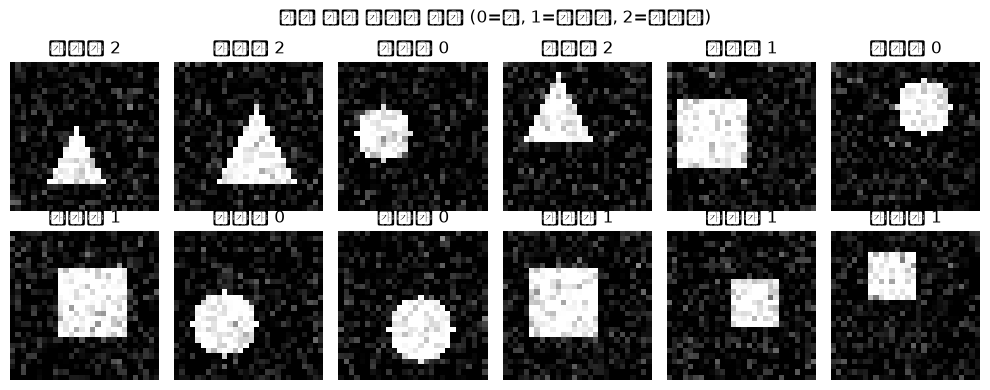

In [3]:
SIZE = 28

def draw_shape(cls, rng):
    img = np.zeros((SIZE, SIZE), dtype=np.float32)
    cy, cx = rng.integers(8, SIZE - 8, 2)   # 도형 중심 (가장자리 여백 확보)
    r = rng.integers(4, 8)                  # 크기
    yy, xx = np.mgrid[0:SIZE, 0:SIZE]       # 모든 픽셀 좌표 그리드
    if cls == 0:    # 원: 중심과의 거리가 r 이하
        img[(xx - cx) ** 2 + (yy - cy) ** 2 <= r ** 2] = 1.0
    elif cls == 1:  # 사각형: 중심 기준 가로/세로 r 이하
        img[(np.abs(xx - cx) <= r) & (np.abs(yy - cy) <= r)] = 1.0
    else:           # 삼각형: 아래로 갈수록 폭이 넓어지는 형태
        dy = yy - (cy - r)
        img[(dy >= 0) & (dy <= 2 * r) & (np.abs(xx - cx) <= dy / 2)] = 1.0
    img += rng.normal(0, 0.15, img.shape)   # 센서 노이즈 흉내
    return np.clip(img, 0, 1)

def make_dataset(n_per_class, rng):
    X, y = [], []
    for cls in range(3):
        for _ in range(n_per_class):
            X.append(draw_shape(cls, rng))
            y.append(cls)
    return np.array(X), np.array(y)

X_train, y_train = make_dataset(200, rng)   # 클래스당 200장 → 총 600장
X_test, y_test = make_dataset(50, rng)      # 클래스당 50장 → 총 150장

fig, axes = plt.subplots(2, 6, figsize=(10, 4))
for ax in axes.ravel():
    i = rng.integers(0, len(X_train))
    ax.imshow(X_train[i], cmap="gray"); ax.set_title(f"클래스 {y_train[i]}"); ax.axis("off")
plt.suptitle("합성 학습 이미지 예시 (0=원, 1=사각형, 2=삼각형)")
plt.tight_layout(); plt.show()


## 3) PyTorch로 CNN 정의하고 학습하기

구조: `Conv(1→8) → ReLU → MaxPool → Conv(8→16) → ReLU → MaxPool → Flatten → FC(784→64) → FC(64→3)`
- 28×28 → (pool) 14×14 → (pool) 7×7 이므로 flatten 후 차원은 `16×7×7 = 784`


In [4]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(0)

# (N, 28, 28) → (N, 1, 28, 28): CNN은 채널 차원이 필요해서 unsqueeze로 채널 축 추가
Xtr = torch.tensor(X_train).unsqueeze(1)
ytr = torch.tensor(y_train, dtype=torch.long)
Xte = torch.tensor(X_test).unsqueeze(1)
yte = torch.tensor(y_test, dtype=torch.long)
train_loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=64, shuffle=True)
test_loader = DataLoader(TensorDataset(Xte, yte), batch_size=128)

class SimpleCNN(nn.Module):
    def __init__(self, num_classes=3):
        super().__init__()
        # Conv2d(입력채널, 출력채널, 커널크기, padding=1)
        # padding=1: 3x3 커널을 써도 이미지 크기가 유지되도록 테두리를 0으로 한 겹 채움
        self.conv1 = nn.Conv2d(1, 8, kernel_size=3, padding=1)    # 1채널(흑백) → 8개의 특징 맵
        self.conv2 = nn.Conv2d(8, 16, kernel_size=3, padding=1)   # 8 → 16 특징 맵 (더 복잡한 패턴)
        self.pool = nn.MaxPool2d(2, 2)    # 2x2 윈도우의 최댓값 → 가로세로 절반 (28→14→7)
        self.relu = nn.ReLU()             # 비선형성도입: 선형층만 쌓으면 의미가 없기 때문
        self.fc1 = nn.Linear(16 * 7 * 7, 64)   # flatten된 특징을 64차원으로 압축
        self.fc2 = nn.Linear(64, num_classes)  # 최종 클래스 로짓 (softmax는 손실 함수가 담당)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))   # (N, 1, 28, 28) → (N, 8, 14, 14)
        x = self.pool(self.relu(self.conv2(x)))   # (N, 8, 14, 14) → (N, 16, 7, 7)
        x = x.flatten(1)                          # (N, 16*7*7) = (N, 784)
        x = self.relu(self.fc1(x))
        return self.fc2(x)                        # (N, 3) 로짓

model = SimpleCNN()
criterion = nn.CrossEntropyLoss()   # 다중클래스 분류의 표준: 내부에 softmax + NLL 포함
optimizer = torch.optim.Adam(model.parameters(), lr=2e-3)   # lr=2e-3으로 20에포크 학습하면 테스트 정확도 99%까지 올라감


에포크 1: 손실=1.0929  테스트 정확도=0.360
에포크 5: 손실=0.8585  테스트 정확도=0.567


에포크 10: 손실=0.5422  테스트 정확도=0.767


에포크 15: 손실=0.1914  테스트 정확도=0.960


에포크 20: 손실=0.0556  테스트 정확도=0.973


/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 54617 (\N{HANGUL SYLLABLE HAG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 49845 (\N{HANGUL SYLLABLE SEUB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 44257 (\N{HANGUL SYLLABLE GOG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 49440 (\N{HANGUL SYLLABLE SEON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 50640 (\N{HANGUL SYLLABLE E}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/

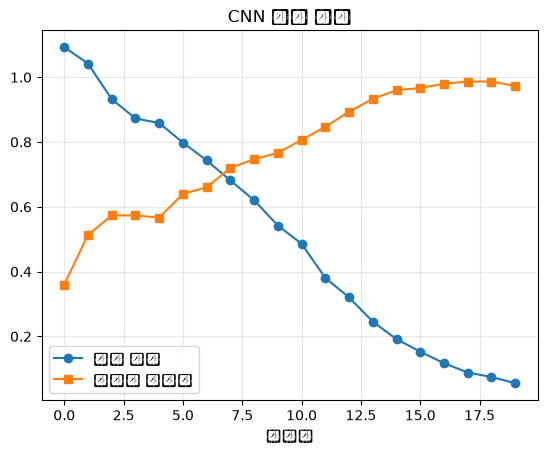

In [5]:
losses, accs = [], []
EPOCHS = 20
for epoch in range(EPOCHS):
    model.train()
    epoch_loss = 0.0
    for xb, yb in train_loader:
        optimizer.zero_grad()          # 이전 배치의 경사를 0으로 초기화 (중요! 누적 방지)
        out = model(xb)
        loss = criterion(out, yb)
        loss.backward()                # 역전파: 모든 층의 가중치에 대한 경사 계산
        optimizer.step()               # 경사를 이용해 가중치 갱신
        epoch_loss += loss.item() * len(yb)
    # 테스트 정확도 계산 (gradient 계산 불필요 → no_grad로 메모리/계산 절약)
    model.eval()
    with torch.no_grad():
        correct = sum((model(xb).argmax(1) == yb).sum().item() for xb, yb in test_loader)
    acc = correct / len(yte)
    losses.append(epoch_loss / len(Xtr)); accs.append(acc)
    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"에포크 {epoch+1}: 손실={losses[-1]:.4f}  테스트 정확도={acc:.3f}")

plt.plot(losses, marker="o", label="학습 손실")
plt.plot(accs, marker="s", label="테스트 정확도")
plt.xlabel("에포크"); plt.legend(); plt.title("CNN 학습 곡선"); plt.grid(alpha=0.3); plt.show()


/tmp/ipykernel_18849/820833276.py:14: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) DejaVu Sans.
  plt.suptitle("테스트 이미지 예측 결과"); plt.tight_layout(); plt.show()
/tmp/ipykernel_18849/820833276.py:14: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) DejaVu Sans.
  plt.suptitle("테스트 이미지 예측 결과"); plt.tight_layout(); plt.show()
/tmp/ipykernel_18849/820833276.py:14: UserWarning: Glyph 49324 (\N{HANGUL SYLLABLE SA}) missing from font(s) DejaVu Sans.
  plt.suptitle("테스트 이미지 예측 결과"); plt.tight_layout(); plt.show()
/tmp/ipykernel_18849/820833276.py:14: UserWarning: Glyph 44033 (\N{HANGUL SYLLABLE GAG}) missing from font(s) DejaVu Sans.
  plt.suptitle("테스트 이미지 예측 결과"); plt.tight_layout(); plt.show()
/tmp/ipykernel_18849/820833276.py:14: UserWarning: Glyph 54805 (\N{HANGUL SYLLABLE HYEONG}) missing from font(s) DejaVu Sans.
  plt.suptitle("테스트 이미지 예측 결과"); plt.tight_layout(); plt.show()
/tmp/ipykernel_18849/820833276.py:14: UserWarning: Glyph 51221 

/tmp/ipykernel_18849/820833276.py:14: UserWarning: Glyph 53580 (\N{HANGUL SYLLABLE TE}) missing from font(s) DejaVu Sans.
  plt.suptitle("테스트 이미지 예측 결과"); plt.tight_layout(); plt.show()
/tmp/ipykernel_18849/820833276.py:14: UserWarning: Glyph 49828 (\N{HANGUL SYLLABLE SEU}) missing from font(s) DejaVu Sans.
  plt.suptitle("테스트 이미지 예측 결과"); plt.tight_layout(); plt.show()
/tmp/ipykernel_18849/820833276.py:14: UserWarning: Glyph 53944 (\N{HANGUL SYLLABLE TEU}) missing from font(s) DejaVu Sans.
  plt.suptitle("테스트 이미지 예측 결과"); plt.tight_layout(); plt.show()
/tmp/ipykernel_18849/820833276.py:14: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  plt.suptitle("테스트 이미지 예측 결과"); plt.tight_layout(); plt.show()
/tmp/ipykernel_18849/820833276.py:14: UserWarning: Glyph 48120 (\N{HANGUL SYLLABLE MI}) missing from font(s) DejaVu Sans.
  plt.suptitle("테스트 이미지 예측 결과"); plt.tight_layout(); plt.show()
/tmp/ipykernel_18849/820833276.py:14: UserWarning: Glyph 51648 (\N{HA

/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 49324 (\N{HANGUL SYLLABLE SA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 44033 (\N{HANGUL SYLLABLE GAG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 54805 (\N{HANGUL SYLLABLE HYEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/us

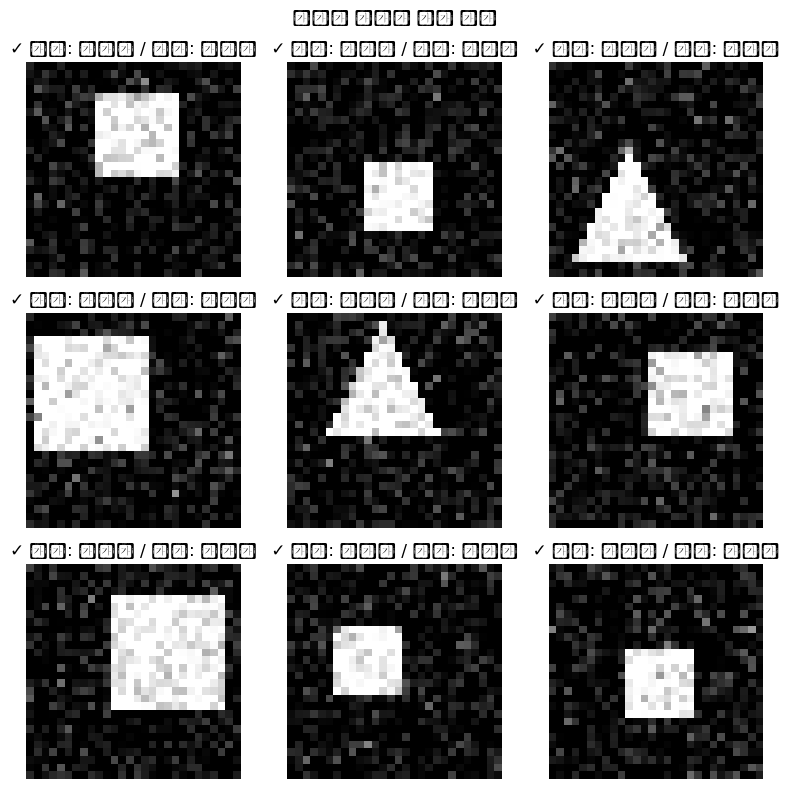

최종 테스트 정확도: 0.9733333333333334


In [6]:
# 테스트 이미지 9장에 대한 예측 결과 시각화
classes = ["원", "사각형", "삼각형"]
model.eval()
with torch.no_grad():
    preds = model(Xte).argmax(1).numpy()

fig, axes = plt.subplots(3, 3, figsize=(8, 8))
for ax in axes.ravel():
    i = rng.integers(0, len(yte))
    ax.imshow(X_test[i], cmap="gray")
    ok = "✓" if preds[i] == y_test[i] else "✗"
    ax.set_title(f"{ok} 예측: {classes[preds[i]]} / 정답: {classes[y_test[i]]}")
    ax.axis("off")
plt.suptitle("테스트 이미지 예측 결과"); plt.tight_layout(); plt.show()
print("최종 테스트 정확도:", (preds == y_test).mean())


## ✅ 정리

- **합성곱**은 커널로 국소 패턴(엣지→모양→복합 특징)을 계층적으로 검출하고, **가중치 공유**로 파라미터를 아낌
- **풀링**은 크기를 줄이고 위치 이동에 대한 불변성을 줌
- CNN은 이미지뿐 아니라 음성, 시계열 등 **격자 구조 데이터**에널리 쓰임 (ResNet, VGG 등은 이 구조를 깊게 쌓은 것)
- 다음: [`05_RNN.ipynb`](./05_RNN.ipynb) — 순서가 있는 데이터를 위한 순환 신경망
